# Computer Vision Portfolio 2 — Assignment 1: Model Forensics

**Team Members:** Chandana Lakshmisagara Udayashankar & Harshavardini Gowrisankar

**Target Model:** `waterbirds_erm_resnet18_biased.pt` (ResNet-18, `landbird` vs. `waterbird`)

---

### Objective
Investigate why a model that reaches 99% (waterbirds) and 98% (landbirds) accuracy on internal evaluation fails on the customer's 5 real-world images. The model weights are **not** retrained or modified; the analysis is a forensic investigation only.

### Notebook Structure
| Section | Task | Lead |
|---|---|---|
| Task 1 | Initial Inspection & Hypothesis Formation | Harshavardini Gowrisankar |
| Task 2 | Design and Perform a Forensic Analysis  | Chandana Lakshmisagara Udayashankar |
| Task 3 | Diagnosis and Verification  | Harshavardini Gowrisankar & Chandana Lakshmisagara Udayashankar|

> **Read-Only Shared Files Rule:** `Start.py`, `waterbirds_model.py`, `waterbirds_erm_resnet18_biased.pt`, and `data/customer_examples/` are imported directly without modification.

## Task 1: Initial Inspection & Hypothesis Formation

Evaluate the pre-trained ResNet-18 classifier on the 5 customer example images, record predictions and softmax confidence scores against the ground-truth species labels, identify systematic failure patterns, and formulate falsifiable hypotheses for forensic testing.

In [93]:
from pathlib import Path
import torch
from torchvision import transforms
from PIL import Image
import pandas as pd
import matplotlib.pyplot as plt

# Import from read-only starter module
from waterbirds_model import load_model, CLASS_NAMES

# Standard ResNet-18 ImageNet preprocessing
PREPROCESS = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225],
    ),
])

# Ground-truth biological class, species name, and observed background
GROUND_TRUTH = {
    "Cape_May_Warbler_0048_162915.jpg": ("landbird", "Cape May Warbler", "land"),
    "Common_Tern_0067_149540.jpg": ("waterbird", "Common Tern", "water"),
    "Slaty_Backed_Gull_0079_796020.jpg": ("waterbird", "Slaty-backed Gull", "land"),
    "Sooty_Albatross_0036_796387.jpg": ("waterbird", "Sooty Albatross", "land"),
    "White_Pelican_0076_96427.jpg": ("waterbird", "White Pelican", "water"),
}

base_dir = Path.cwd()
checkpoint_path = base_dir / "waterbirds_erm_resnet18_biased.pt"
images_dir = base_dir / "data" / "customer_examples"
results_dir = base_dir / "results"
results_dir.mkdir(parents=True, exist_ok=True)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = load_model(str(checkpoint_path), device)
print(f"Loaded model on {device}. Class mapping: {CLASS_NAMES}")

Loaded model on cpu. Class mapping: {0: 'landbird', 1: 'waterbird'}


In [94]:
valid_exts = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
image_paths = sorted(
    p for p in images_dir.iterdir()
    if p.is_file() and p.suffix.lower() in valid_exts
)

records = []
loaded_images = []

with torch.no_grad():
    for img_path in image_paths:
        pil_img = Image.open(img_path).convert("RGB")
        loaded_images.append((img_path.name, pil_img))

        input_tensor = PREPROCESS(pil_img).unsqueeze(0).to(device)
        logits = model(input_tensor)
        probs = torch.softmax(logits, dim=1).squeeze(0).cpu()

        pred_idx = int(torch.argmax(probs).item())
        pred_label = CLASS_NAMES[pred_idx]
        prob_landbird = float(probs[0].item())
        prob_waterbird = float(probs[1].item())
        confidence = float(probs[pred_idx].item())

        gt_bird, species, gt_bg = GROUND_TRUTH[img_path.name]
        is_correct = pred_label == gt_bird

        records.append({
            "filename": img_path.name,
            "species": species,
            "ground_truth_bird": gt_bird,
            "ground_truth_background": gt_bg,
            "predicted_class": pred_label,
            "confidence": round(confidence, 4),
            "prob_landbird": round(prob_landbird, 4),
            "prob_waterbird": round(prob_waterbird, 4),
            "correct": is_correct,
        })

df_results = pd.DataFrame(records)
csv_path = results_dir / "task1_predictions.csv"
df_results.to_csv(csv_path, index=False)

overall_acc = df_results["correct"].mean() * 100
waterbird_acc = df_results[df_results["ground_truth_bird"] == "waterbird"]["correct"].mean() * 100
print(f"Overall Accuracy: {overall_acc:.1f}% ({df_results['correct'].sum()}/{len(df_results)})")
print(f"Waterbird Accuracy: {waterbird_acc:.1f}% (2/4)")

df_results

Overall Accuracy: 60.0% (3/5)
Waterbird Accuracy: 50.0% (2/4)


,filename,species,ground_truth_bird,ground_truth_background,predicted_class,confidence,prob_landbird,prob_waterbird,correct
0,Cape_May_Warbler_0048_162915.jpg,Cape May Warbler,landbird,land,landbird,1.0000,1.0000,0.0000,True
1,Common_Tern_0067_149540.jpg,Common Tern,waterbird,water,waterbird,1.0000,0.0000,1.0000,True
2,Slaty_Backed_Gull_0079_796020.jpg,Slaty-backed Gull,waterbird,land,landbird,0.9564,0.9564,0.0436,False
3,Sooty_Albatross_0036_796387.jpg,Sooty Albatross,waterbird,land,landbird,0.9537,0.9537,0.0463,False
4,White_Pelican_0076_96427.jpg,White Pelican,waterbird,water,waterbird,1.0000,0.0000,1.0000,True


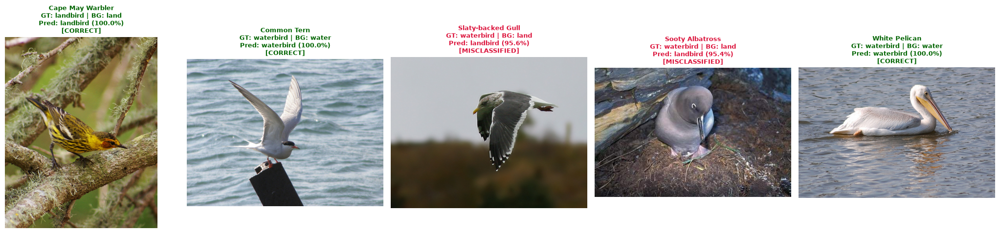

Saved inspection grid to: /Users/chandanalakshmisagaraudayashankar/Desktop/CV-Forensics-Edge/Assignment-1-Model_Forensics/results/task1_inspection_grid.png


In [95]:
fig, axes = plt.subplots(1, len(loaded_images), figsize=(4.2 * len(loaded_images), 4.8))
if len(loaded_images) == 1:
    axes = [axes]

for idx, ((fname, pil_img), row) in enumerate(zip(loaded_images, records)):
    axes[idx].imshow(pil_img)
    axes[idx].axis("off")
    status = "CORRECT" if row["correct"] else "MISCLASSIFIED"
    title_color = "darkgreen" if row["correct"] else "crimson"

    title_text = (
        f"{row['species']}\n"
        f"GT: {row['ground_truth_bird']} | BG: {row['ground_truth_background']}\n"
        f"Pred: {row['predicted_class']} ({row['confidence'] * 100:.1f}%)\n"
        f"[{status}]"
    )
    axes[idx].set_title(title_text, fontsize=9, color=title_color, fontweight="bold")

grid_path = results_dir / "task1_inspection_grid.png"
plt.tight_layout()
plt.savefig(grid_path, dpi=200, bbox_inches="tight")
plt.show()
print(f"Saved inspection grid to: {grid_path}")

## Pattern Analysis & Formulated Hypotheses

### 1. Summary of Empirical Findings
* **Overall Customer Accuracy:** **60.0% (3/5)**; **Waterbird Accuracy:** **50.0% (2/4)**.
* **Background-Aligned Samples (100% Accuracy — 3/3):**
  * `Cape_May_Warbler_0048_162915.jpg` (*landbird* on *land*) $\rightarrow$ predicted `landbird` (**100.0%** confidence).
  * `Common_Tern_0067_149540.jpg` (*waterbird* on *water*) $\rightarrow$ predicted `waterbird` (**100.0%** confidence).
  * `White_Pelican_0076_96427.jpg` (*waterbird* on *water*) $\rightarrow$ predicted `waterbird` (**100.0%** confidence).
* **Background-Shifted Samples (0% Accuracy — 0/2):**
  * `Slaty_Backed_Gull_0079_796020.jpg` (*waterbird* flying over *grass/land*) $\rightarrow$ misclassified as `landbird` (**95.6%** confidence).
  * `Sooty_Albatross_0036_796387.jpg` (*waterbird* on *rocky nest/land*) $\rightarrow$ misclassified as `landbird` (**95.4%** confidence).

### 2. Observed Visual Pattern
Across all 5 images, the model's prediction aligns **100% with the background habitat** (`water` $\rightarrow$ `waterbird`, `foliage/grass/rock` $\rightarrow$ `landbird`) rather than the bird's morphological features, exhibiting extreme overconfidence (>95%) even when wrong.

### 3. Formulated Hypotheses
* **Hypothesis 1 (Spurious Background Shortcut):** The ResNet-18 classifier predicts the class based on **background habitat cues** (water textures $\rightarrow$ `waterbird`; foliage, grass, or rock $\rightarrow$ `landbird`) rather than morphological bird features (beak, wings, plumage), causing waterbirds photographed on land to be misclassified with >95% confidence.

* **Hypothesis 2 (Internal Evaluation Distribution Bias):** The model achieved **99% accuracy on waterbirds** and **98% accuracy on landbirds** during internal evaluation because the internal dataset consisted predominantly of canonical background-aligned pairs (*waterbirds on water*, *landbirds on land*), masking the model's failure on out-of-distribution backgrounds.

## Task 2: Design and Perform a Forensic Analysis 

In this task, we investigate why the ResNet-18 model makes incorrect predictions on some customer images. We use Grad-CAM, Occlusion Sensitivity and input interventions to understand whether the model focuses on the bird or its background while making predictions.


### 1. Grad-CAM

We use Grad-CAM to visualize which regions of an image influence the model's predictions. This helps us investigate whether the model focuses on the bird or its background.

In [96]:
import torch.nn.functional as F

def generate_gradcam(image, target_class):
    captured = {}

    def forward_hook(module, inputs, output):
        captured["activations"] = output
        output.register_hook(
            lambda grad: captured.update({"gradients": grad})
        )

    handle = model.layer4.register_forward_hook(forward_hook)

    input_tensor = PREPROCESS(image).unsqueeze(0).to(device)

    model.zero_grad()
    logits = model(input_tensor)
    logits[0, target_class].backward()

    activations = captured["activations"]
    gradients = captured["gradients"]

    weights = gradients.mean(dim=(2, 3), keepdim=True)
    cam = (weights * activations).sum(dim=1, keepdim=True)
    cam = F.relu(cam)

    cam = F.interpolate(
        cam, size=(224, 224), mode="bilinear", align_corners=False
    )

    cam = cam.squeeze().detach().cpu()
    cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)

    handle.remove()

    return cam, logits.detach()

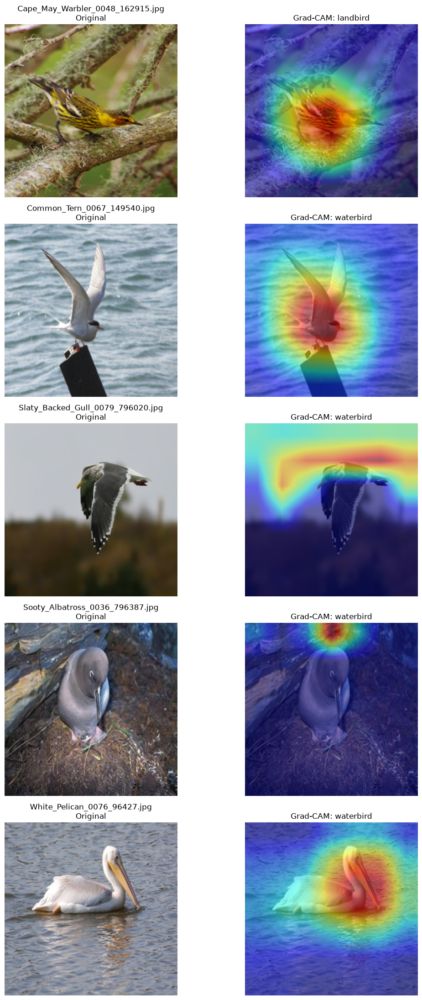

In [97]:
fig, axes = plt.subplots(5, 2, figsize=(12, 22))

for i, path in enumerate(image_paths):
    image = Image.open(path).convert("RGB")
    true_class = GROUND_TRUTH[path.name][0]
    target_class = 0 if true_class == "landbird" else 1

    cam, logits = generate_gradcam(image, target_class)

    axes[i, 0].imshow(image.resize((224, 224)))
    axes[i, 0].set_title(f"{path.name}\nOriginal")

    axes[i, 1].imshow(image.resize((224, 224)))
    axes[i, 1].imshow(cam, cmap="jet", alpha=0.5)
    axes[i, 1].set_title(f"Grad-CAM: {true_class}")

    for ax in axes[i]:
        ax.axis("off")

plt.tight_layout()
plt.show()

### Grad-CAM: Observations and Conclusion

The Grad-CAM visualisations show that the model focuses on different regions across the five images. In some cases, activation is concentrated on the bird, while in others it also extends to the surrounding background.

This suggests that both bird features and background information may influence the model's predictions. However, Grad-CAM highlights regions associated with a prediction and does not prove that those regions causally determine the classification. Therefore, the visualisations provide supporting evidence rather than definitive proof of background dependence.

### 2. Occlusion Sensitivity

We cover small regions of each image with a grey patch and observe how the model's prediction probability changes. This helps identify whether the bird or the background has a greater influence on the prediction.

In [98]:
def predict_probability(image_tensor, target_class):
    with torch.no_grad():
        logits = model(image_tensor)
        probabilities = torch.softmax(logits, dim=1)
    return probabilities[0, target_class].item()


def occlusion_sensitivity(image, target_class, patch_size=32, stride=16):
    image_tensor = PREPROCESS(image).unsqueeze(0).to(device)

    original_probability = predict_probability(image_tensor, target_class)

    occlusion_map = torch.zeros(224, 224)

    for y in range(0, 224 - patch_size + 1, stride):
        for x in range(0, 224 - patch_size + 1, stride):

            occluded = image_tensor.clone()
            occluded[:, :, y:y + patch_size, x:x + patch_size] = 0

            new_probability = predict_probability(occluded, target_class)

            probability_drop = original_probability - new_probability

            occlusion_map[
                y:y + patch_size,
                x:x + patch_size
            ] += probability_drop

    return occlusion_map, original_probability

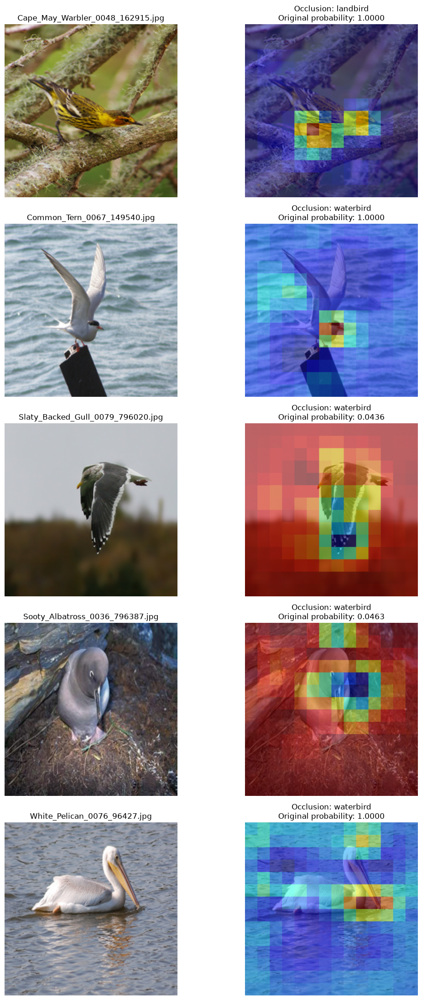

In [99]:
fig, axes = plt.subplots(5, 2, figsize=(12, 22))

for i, path in enumerate(image_paths):
    image = Image.open(path).convert("RGB")

    true_class = GROUND_TRUTH[path.name][0]
    target_class = 0 if true_class == "landbird" else 1

    occ_map, original_prob = occlusion_sensitivity(
        image, target_class
    )

    axes[i, 0].imshow(image.resize((224, 224)))
    axes[i, 0].set_title(path.name)

    axes[i, 1].imshow(image.resize((224, 224)))
    axes[i, 1].imshow(occ_map, cmap="jet", alpha=0.5)
    axes[i, 1].set_title(
        f"Occlusion: {true_class}\nOriginal probability: {original_prob:.4f}"
    )

    for ax in axes[i]:
        ax.axis("off")

plt.tight_layout()
plt.show()

### Occlusion Sensitivity: Observations and Conclusion

Occlusion sensitivity shows how the model's class probabilities change when different image regions are covered. The Slaty-backed Gull and Sooty Albatross received very low probabilities for their correct classes.

The results suggest that different image regions influence the predictions. However, occlusion introduces artificial changes to the input, and the probability changes may depend on the selected patch size and position. Therefore, these results should be interpreted cautiously and do not independently establish which features cause the classification errors.

### 3. Controlled Input Interventions

We modify the customer images to study how the model responds to changes in the bird and its background. We compare the predictions and probabilities before and after these changes to understand which features influence the model more.

In [100]:
import numpy as np
from torchvision.models.segmentation import (
    deeplabv3_resnet50,
    DeepLabV3_ResNet50_Weights
)

weights = DeepLabV3_ResNet50_Weights.COCO_WITH_VOC_LABELS_V1

segmentation_model = deeplabv3_resnet50(
    weights=weights
).to(device)

segmentation_model.eval()

bird_class = weights.meta["categories"].index("bird")

def extract_bird(image):
    input_tensor = weights.transforms()(image).unsqueeze(0).to(device)

    with torch.no_grad():
        output = segmentation_model(input_tensor)["out"][0]

    prediction = output.argmax(dim=0).cpu().numpy()
    bird_mask = (prediction == bird_class).astype(np.uint8)

    bird_mask = cv2.resize(
        bird_mask,
        image.size,
        interpolation=cv2.INTER_NEAREST
    )

    return bird_mask

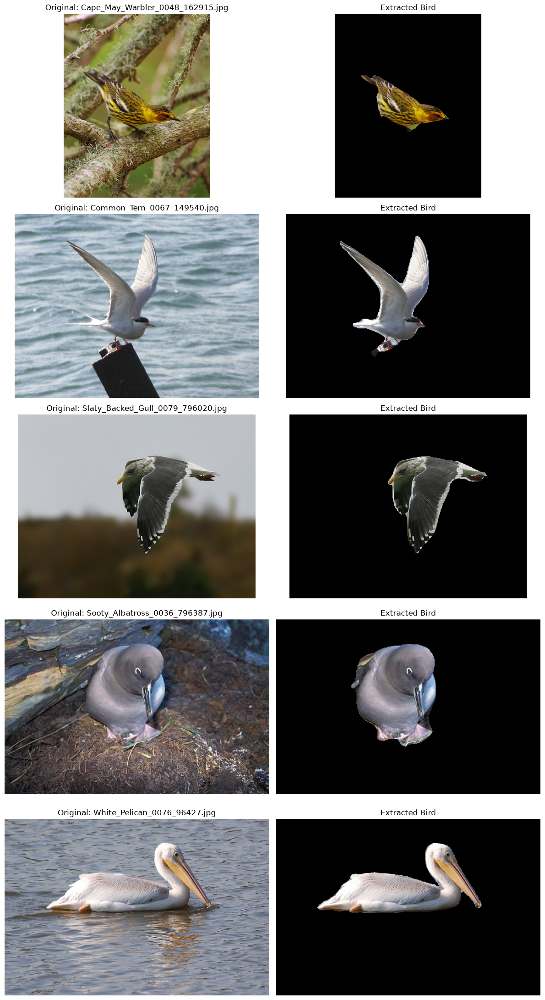

In [101]:
fig, axes = plt.subplots(5, 2, figsize=(12, 22))

for i, path in enumerate(image_paths):
    image = Image.open(path).convert("RGB")
    image_np = np.array(image)

    bird_mask = extract_bird(image)

    bird_only = image_np * bird_mask[:, :, np.newaxis]

    axes[i, 0].imshow(image_np)
    axes[i, 0].set_title(f"Original: {path.name}")

    axes[i, 1].imshow(bird_only)
    axes[i, 1].set_title("Extracted Bird")

    for ax in axes[i]:
        ax.axis("off")

plt.tight_layout()
plt.show()

### 3.1 Bird-Only and Background-Only Experiments

We create bird-only and background-only versions of the five images using the segmentation masks. We compare the model's predictions and probabilities for all three versions to study the influence of bird and background information.

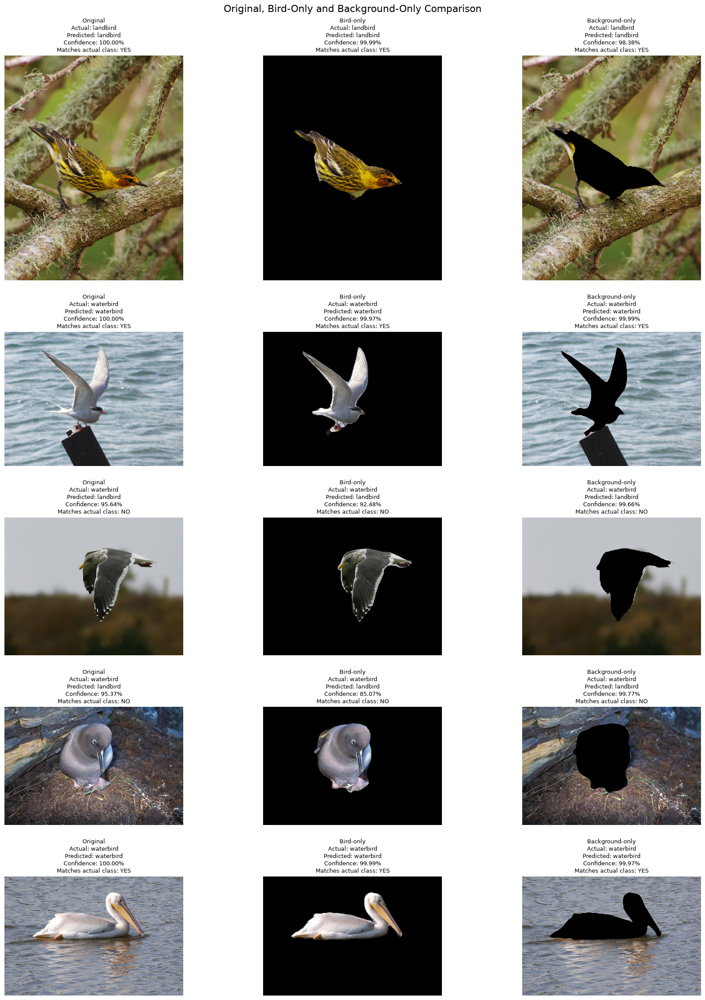

In [102]:
height_ratios = []

for path in image_paths:
    img = Image.open(path)
    height_ratios.append(img.height / img.width)

fig = plt.figure(figsize=(18, 23))

gs = fig.add_gridspec(
    5, 3,
    height_ratios=height_ratios,
    hspace=0.35,
    wspace=0.04
)

axes = np.array([
    [fig.add_subplot(gs[i, j]) for j in range(3)]
    for i in range(5)
])

for i, path in enumerate(image_paths):

    image = Image.open(path).convert("RGB")
    image_np = np.array(image)

    actual_class = GROUND_TRUTH[path.name][0]

    bird_mask = extract_bird(image)

    bird_only = image_np * bird_mask[:, :, np.newaxis]
    background_only = image_np * (1 - bird_mask[:, :, np.newaxis])

    versions = [
        ("Original", image_np),
        ("Bird-only", bird_only),
        ("Background-only", background_only)
    ]

    for j, (version_name, version_image) in enumerate(versions):

        input_image = Image.fromarray(version_image)
        input_tensor = PREPROCESS(input_image).unsqueeze(0).to(device)

        with torch.no_grad():
            logits = model(input_tensor)
            probabilities = torch.softmax(logits, dim=1)[0]

        predicted_class = CLASS_NAMES[logits.argmax(dim=1).item()]
        confidence = probabilities.max().item() * 100

        matches = "YES" if predicted_class == actual_class else "NO"

        axes[i, j].imshow(version_image)

        axes[i, j].set_title(
            f"{version_name}\n"
            f"Actual: {actual_class}\n"
            f"Predicted: {predicted_class}\n"
            f"Confidence: {confidence:.2f}%\n"
            f"Matches actual class: {matches}",
            fontsize=9,
            pad=6
        )

        axes[i, j].axis("off")

fig.suptitle(
    "Original, Bird-Only and Background-Only Comparison",
    fontsize=16,
    y=0.99
)

fig.subplots_adjust(
    top=0.94,
    bottom=0.02,
    left=0.02,
    right=0.98
)

plt.show()

### Bird-Only and Background-Only: Observations and Conclusion

The model retained the same predicted classes for the original, bird-only and background-only versions of all five images. Notably, the background-only images produced highly confident predictions, including for the two misclassified birds.

This suggests that background information can strongly influence the model's predictions. However, DeepLabV3 did not capture every bird detail, particularly some legs and fine body regions. The artificial black regions in the modified images may also influence predictions. Therefore, the experiment provides evidence of background influence but does not prove exclusive reliance on background information.

### 3.2 Background-Swap Experiment

We replace the background of a bird image with the background from another customer image while keeping the original bird unchanged. We then compare the model's predictions before and after the background replacement to investigate whether changing the background affects classification.

This experiment helps us understand whether the model relies on bird features, background information, or both when making predictions.

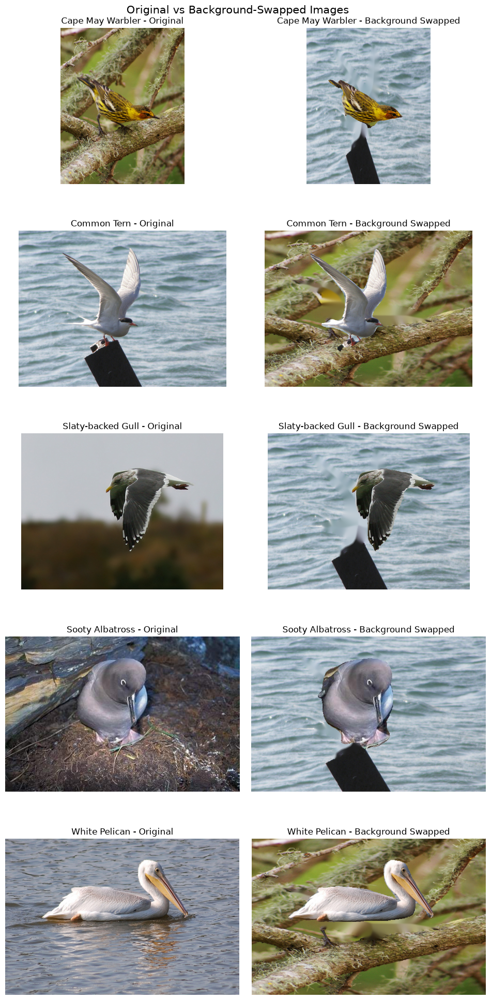

In [105]:
swapped_images = {}

for path in image_paths:

    image = Image.open(path).convert("RGB")
    image_np = np.array(image)

    bird_mask = extract_bird(image)

    actual_class, species, background_type = GROUND_TRUTH[path.name]
    opposite_type = "water" if background_type == "land" else "land"

    donor_path = next(
        p for p in image_paths
        if GROUND_TRUTH[p.name][2] == opposite_type
    )

    donor_image = Image.open(donor_path).convert("RGB")
    donor_np = np.array(donor_image)

    donor_mask = extract_bird(donor_image)

    kernel = np.ones((9, 9), np.uint8)
    donor_mask = cv2.dilate(donor_mask, kernel, iterations=1)

    clean_donor = cv2.inpaint(
        donor_np,
        donor_mask * 255,
        5,
        cv2.INPAINT_TELEA
    )

    clean_donor = cv2.resize(
        clean_donor,
        (image.width, image.height)
    )

    swapped_image = np.where(
        bird_mask[:, :, np.newaxis] == 1,
        image_np,
        clean_donor
    ).astype(np.uint8)

    swapped_images[path.name] = swapped_image


fig, axes = plt.subplots(5, 2, figsize=(12, 22))

for i, path in enumerate(image_paths):

    original = np.array(Image.open(path).convert("RGB"))
    swapped = swapped_images[path.name]

    species = GROUND_TRUTH[path.name][1]

    axes[i, 0].imshow(original)
    axes[i, 0].set_title(f"{species} - Original")

    axes[i, 1].imshow(swapped)
    axes[i, 1].set_title(f"{species} - Background Swapped")

    for ax in axes[i]:
        ax.axis("off")

fig.suptitle("Original vs Background-Swapped Images", fontsize=15)

fig.subplots_adjust(
    top=0.96,
    hspace=0.3,
    wspace=0.05
)

plt.show()

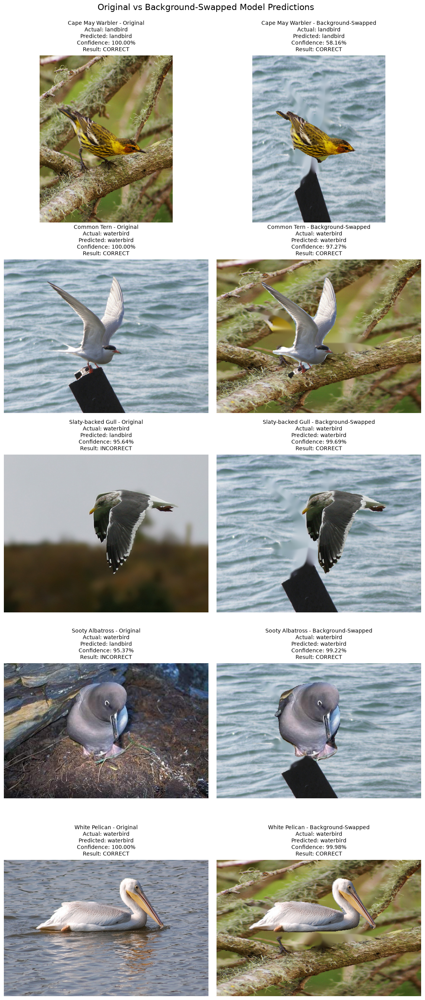

In [106]:
fig, axes = plt.subplots(5, 2, figsize=(14, 27))

for i, path in enumerate(image_paths):

    species = GROUND_TRUTH[path.name][1]
    actual_class = GROUND_TRUTH[path.name][0]

    original_image = Image.open(path).convert("RGB")
    original_tensor = PREPROCESS(original_image).unsqueeze(0).to(device)

    swapped_array = swapped_images[path.name]
    swapped_image = Image.fromarray(swapped_array)
    swapped_tensor = PREPROCESS(swapped_image).unsqueeze(0).to(device)

    versions = [
        ("Original", original_image, original_tensor),
        ("Background-Swapped", swapped_image, swapped_tensor)
    ]

    for j, (version_name, display_image, input_tensor) in enumerate(versions):

        with torch.no_grad():
            logits = model(input_tensor)
            probabilities = torch.softmax(logits, dim=1)[0]

        predicted_class = CLASS_NAMES[logits.argmax(dim=1).item()]
        confidence = probabilities.max().item() * 100

        status = (
            "CORRECT"
            if predicted_class == actual_class
            else "INCORRECT"
        )

        axes[i, j].imshow(display_image)

        axes[i, j].set_title(
            f"{species} - {version_name}\n"
            f"Actual: {actual_class}\n"
            f"Predicted: {predicted_class}\n"
            f"Confidence: {confidence:.2f}%\n"
            f"Result: {status}",
            fontsize=10,
            pad=8
        )

        axes[i, j].axis("off")

fig.suptitle(
    "Original vs Background-Swapped Model Predictions",
    fontsize=16,
    y=0.99
)

fig.subplots_adjust(
    top=0.94,
    bottom=0.02,
    hspace=0.18,
    wspace=0.04
)

plt.show()

### Background-Swap: Observations and Conclusion

After replacing the original backgrounds with backgrounds of the opposite type, the Slaty-backed Gull and Sooty Albatross changed from incorrect landbird predictions to correct waterbird predictions.

The Cape May Warbler remained classified as a landbird, although its confidence decreased from 100% to 58.16%. The Common Tern and White Pelican retained their correct predictions.

These results provide additional evidence that background information influences classification. However, imperfect segmentation and visible inpainting artefacts may also have affected the predictions. Therefore, the changes cannot be attributed exclusively to the replacement backgrounds.

### Overall Conclusion of the Forensic Analysis

Our experiments indicate that the model's predictions are influenced by background information and are not based exclusively on bird features.

The background-swap experiment provides particularly strong supporting evidence: two initially misclassified waterbirds were correctly classified after their backgrounds were changed.

These findings suggest that the model has learned spurious correlations between bird classes and their typical backgrounds. Such correlations may lead to incorrect predictions when the model encounters unfamiliar background conditions.

Our findings support the influence of background information on the model's predictions. However, segmentation and image modification artefacts limit the certainty of this conclusion.


## Task 3: Diagnosis and Verification

### 3.1 Summary of Evidence from Task 1 and Task 2

**Task 1 – Initial Inspection**
- The model correctly classified 3 out of 5 customer images.
- Slaty-backed Gull and Sooty Albatross were incorrectly classified as landbirds, despite being waterbirds.
- Both misclassified birds had land backgrounds.

**Task 2 – Forensic Experiments**
- **Grad-CAM:** Activations covered regions of both birds and backgrounds.
- **Occlusion Sensitivity:** Covering image regions changed class probabilities.
- **Bird-only / Background-only:** Original predictions remained unchanged, even when only the background was visible.
- **Background Swap:** Both initially misclassified waterbirds became correctly classified after background replacement.

### 3.2 Evaluation of Initial Hypotheses

| Hypothesis | Assessment | Evidence |
|---|---|---|
| H1: Background shortcut | Supported | Two incorrect predictions became correct after background swapping. |
| H2: Internal evaluation distribution bias | Plausible, not verified | Original training and test distributions were unavailable. |
| H3: Global colour and texture cues | Partially supported | Background changes affected predictions, but colour and texture were not isolated. |

### 3.3 Explaining High Internal Evaluation Accuracy

The model achieved 99% accuracy for waterbirds and 98% for landbirds. One possible explanation is that training and test datasets contained similar correlations between bird classes and backgrounds.

$$
Acc_{\text{internal}} =
p_{\text{aligned}} \cdot Acc_{\text{aligned}}
+
(1-p_{\text{aligned}}) \cdot Acc_{\text{shifted}}
$$

When most test images follow familiar bird-background patterns, the model may achieve high accuracy despite performing poorly on unfamiliar combinations.

The original training and test distributions were unavailable, so this explanation could not be directly verified.

### 3.4 Quantitative Evidence: Background Swap

| Bird Species | Original Prediction | Background-Swapped Prediction |
|---|---|---|
| Cape May Warbler | Landbird (100%) | Landbird (58.16%) |
| Common Tern | Waterbird (100%) | Waterbird (97.27%) |
| Slaty-backed Gull | Landbird (95.64%) | Waterbird (99.69%) |
| Sooty Albatross | Landbird (95.37%) | Waterbird (99.22%) |
| White Pelican | Waterbird (100%) | Waterbird (99.98%) |

### 3.5 Final Forensic Diagnosis

The combined evidence indicates that the ResNet-18 model relies partly on background-related shortcuts rather than exclusively on bird features.

The background-swap experiment provides particularly strong evidence: two initially misclassified waterbirds became correctly classified after their backgrounds were replaced.

Therefore, the model is vulnerable to background distribution shifts. Imperfect segmentation and inpainting artefacts should be considered when interpreting these results.
